# Klasifikasi Audio: Berisik vs Non-Berisik

Notebook ini membangun model klasifikasi audio menggunakan fitur Librosa (RMS, Spectral Centroid, Zero Crossing Rate, dan MFCC) serta Random Forest. Notebook juga mengekspor CSV inventaris audio dan CSV fitur, lalu memvisualisasikan waveform/time series audio uji dengan warna sesuai hasil prediksi setiap segmen.

## Struktur dataset

Siapkan folder seperti berikut:

```text
dataset/
├── berisik/
│   ├── rekaman_01.wav
│   └── ...
└── non-berisik/
    ├── rekaman_01.wav
    └── ...
```

Format yang dicoba: WAV, MP3, FLAC, OGG, M4A, AAC, atau WMA (dukungan bergantung pada FFmpeg/librosa yang terpasang).

**Penting:** gunakan rekaman asli dan label yang konsisten. Model tidak dilatih menggunakan data dummy.

## 1. Instalasi dependensi
Jalankan sel berikut di Jupyter Notebook atau Google Colab. Jika memakai Colab, unggah dataset atau hubungkan Google Drive dan sesuaikan `DATA_DIR`.

In [1]:
%pip install -q librosa soundfile scikit-learn pandas numpy matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import pustaka dan konfigurasi

Audio diubah menjadi mono dengan sample rate 16 kHz dan dibagi menjadi segmen 5 detik. Segmen terakhir yang berdurasi minimal 2 detik akan di-padding agar panjangnya seragam.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, balanced_accuracy_score, f1_score
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

# Sesuaikan lokasi dataset dengan lingkungan Anda.
# Contoh Colab: Path("/content/drive/MyDrive/audio-psd")
DATA_DIR = Path(".") if Path("berisik").exists() else Path("/content/drive/MyDrive/audio-psd")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 16_000
SEGMENT_SECONDS = 5
MIN_SEGMENT_SECONDS = 2
RANDOM_STATE = 42

LABEL_DIRS = {
    "berisik": DATA_DIR / "berisik",
    "non_berisik": DATA_DIR / "non-berisik",
}

AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".ogg", ".m4a", ".aac", ".wma"}

print("Lokasi dataset:", DATA_DIR.resolve())
for label, folder in LABEL_DIRS.items():
    print(f"{label}: {folder} | tersedia:", folder.exists())

Lokasi dataset: D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA
berisik: berisik | tersedia: True
non_berisik: non-berisik | tersedia: True


## 3. Periksa jumlah file dan ekspor inventaris CSV

Sel ini menghitung jumlah file audio per kelas. CSV inventaris langsung dibuat setelah pemeriksaan, sehingga Anda dapat melihat file apa saja yang ditemukan dan kelas asalnya. Jika folder kelas kosong, proses dihentikan dengan pesan yang jelas.

In [3]:
files_by_label = {}
for label, folder in LABEL_DIRS.items():
    files_by_label[label] = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS
    ) if folder.exists() else []

counts = {label: len(paths) for label, paths in files_by_label.items()}
count_df = pd.DataFrame({
    "kelas": list(counts.keys()),
    "jumlah_file": list(counts.values())
})
display(count_df)

# CSV inventaris dibuat tepat setelah pemeriksaan jumlah file.
inventory_rows = []
for label, paths in files_by_label.items():
    for path in paths:
        inventory_rows.append({
            "kelas": label,
            "nama_file": path.name,
            "path_file": str(path.resolve()),
            "ekstensi": path.suffix.lower(),
            "ukuran_byte": path.stat().st_size
        })

inventory_df = pd.DataFrame(
    inventory_rows,
    columns=["kelas", "nama_file", "path_file", "ekstensi", "ukuran_byte"]
)
inventory_csv = OUTPUT_DIR / "inventaris_audio.csv"
inventory_df.to_csv(inventory_csv, index=False, encoding="utf-8-sig")
print(f"CSV inventaris tersimpan: {inventory_csv.resolve()}")
display(inventory_df.head(10))

if any(count == 0 for count in counts.values()):
    raise FileNotFoundError(
        f"Dataset belum lengkap. Pastikan folder '{LABEL_DIRS['berisik']}' "
        f"dan '{LABEL_DIRS['non_berisik']}' masing-masing berisi file audio."
    )

,kelas,jumlah_file
0,berisik,100
1,non_berisik,100


CSV inventaris tersimpan: D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\output\inventaris_audio.csv


,kelas,nama_file,path_file,ekstensi,ukuran_byte
0,berisik,24-003 berisik (1).mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,722276
1,berisik,24-003 berisik (2).mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,1230720
2,berisik,24-003 berisik (3).mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,1203840
3,berisik,24-006 berisik 1.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,737950
4,berisik,24-006 berisik 2.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,729172
5,berisik,24-006 berisik 3.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,743592
6,berisik,24-007 berisikk 1.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,240621
7,berisik,24-007 berisikkk 2.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,240621
8,berisik,24-007 berisikkk 3.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,240621
9,berisik,24-026 berisik 1.mp3,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,.mp3,242057


## 4. Fungsi preprocessing dan ekstraksi fitur

Fitur yang digunakan:
- **RMS**: energi/amplitudo rata-rata.
- **Spectral Centroid**: pusat massa spektrum.
- **Zero Crossing Rate (ZCR)**: laju perubahan tanda sinyal.
- **MFCC**: ringkasan karakteristik spektral.

Mean dan standar deviasi dihitung untuk setiap fitur pada tiap segmen, menghasilkan 32 fitur per segmen.

In [4]:
N_MFCC = 13

def extract_features(y, sr):
    """Menghasilkan 32 fitur ringkasan dari satu segmen audio."""
    y = np.asarray(y, dtype=np.float32)
    if y.size == 0:
        raise ValueError("Audio kosong.")

    rms = librosa.feature.rms(y=y)[0]
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)

    features = {}
    for name, values in [
        ("rms", rms),
        ("spectral_centroid", centroid),
        ("zcr", zcr),
    ]:
        features[f"{name}_mean"] = float(np.mean(values))
        features[f"{name}_std"] = float(np.std(values))

    for i in range(N_MFCC):
        features[f"mfcc_{i+1}_mean"] = float(np.mean(mfcc[i]))
        features[f"mfcc_{i+1}_std"] = float(np.std(mfcc[i]))
    return features


def load_audio(path, sr=SAMPLE_RATE):
    """Muat audio mono dan resample ke sample rate target dengan fallback otomatis."""
    try:
        y, _ = librosa.load(str(path), sr=sr, mono=True)
        if y.size == 0:
            raise ValueError(f"Audio kosong: {path}")
        return y.astype(np.float32)
    except Exception:
        # Fallback otomatis jika PySoundFile gagal pada header stream AAC/MP3
        try:
            import imageio_ffmpeg, subprocess
            ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()
            cmd = [ffmpeg_exe, "-i", str(path), "-vn", "-f", "s16le", "-ac", "1", "-ar", str(sr), "-"]
            p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL)
            out, _ = p.communicate()
            if out:
                return np.frombuffer(out, dtype=np.int16).astype(np.float32) / 32768.0
        except Exception:
            pass
        raise


def audio_to_segments(path, sr=SAMPLE_RATE,
                      segment_seconds=SEGMENT_SECONDS):
    """Muat audio dan pecah menjadi segmen berdurasi tetap."""
    y = load_audio(path, sr=sr)
    segment_length = int(sr * segment_seconds)
    min_length = int(sr * MIN_SEGMENT_SECONDS)
    segments = []

    for start in range(0, len(y), segment_length):
        segment = y[start:start + segment_length]
        if len(segment) < min_length:
            continue
        if len(segment) < segment_length:
            segment = np.pad(segment, (0, segment_length - len(segment)))
        segments.append(segment.astype(np.float32))

    return segments


## 5. Bangun tabel fitur dan ekspor CSV

Setiap baris mewakili satu segmen audio. `group_id` menyimpan file sumber agar segmen dari file yang sama tidak tersebar di data latih dan data uji. Dataset fitur diekspor ke `output/fitur_audio.csv`.

In [5]:
rows = []
errors = []

for label, paths in files_by_label.items():
    for path in paths:
        try:
            segments = audio_to_segments(path)
            if not segments:
                errors.append((str(path), "Audio terlalu pendek atau kosong"))
                continue

            for segment_index, segment in enumerate(segments):
                feat = extract_features(segment, SAMPLE_RATE)
                feat.update({
                    "label": label,
                    "group_id": str(path.resolve()),
                    "segment_index": segment_index,
                    "start_time_sec": segment_index * SEGMENT_SECONDS,
                    "end_time_sec": (segment_index + 1) * SEGMENT_SECONDS,
                    "source_file": path.name,
                })
                rows.append(feat)
        except Exception as exc:
            errors.append((str(path), str(exc)))

df = pd.DataFrame(rows)
print("Jumlah segmen berhasil diproses:", len(df))
print("Jumlah file sumber:", df["group_id"].nunique() if not df.empty else 0)

if errors:
    print(f"\nFile yang gagal diproses: {len(errors)}")
    display(pd.DataFrame(errors, columns=["file", "alasan"]).head(20))
    pd.DataFrame(errors, columns=["file", "alasan"]).to_csv(
        OUTPUT_DIR / "log_file_gagal.csv", index=False, encoding="utf-8-sig"
    )

if df.empty:
    raise ValueError("Tidak ada segmen yang berhasil diproses. Periksa dataset dan dependensi.")

feature_cols = [
    c for c in df.columns
    if c.startswith(("rms_", "spectral_centroid_", "zcr_", "mfcc_"))
]
features_csv = OUTPUT_DIR / "fitur_audio.csv"
df.to_csv(features_csv, index=False, encoding="utf-8-sig")
print(f"CSV fitur tersimpan: {features_csv.resolve()}")
print("Jumlah fitur:", len(feature_cols))
display(df.head())
display(df["label"].value_counts().rename_axis("kelas").to_frame("jumlah_segmen"))

Jumlah segmen berhasil diproses: 1234
Jumlah file sumber: 200
CSV fitur tersimpan: D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\output\fitur_audio.csv
Jumlah fitur: 32


,rms_mean,rms_std,spectral_centroid_mean,spectral_centroid_std,zcr_mean,zcr_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,label,group_id,segment_index,start_time_sec,end_time_sec,source_file
0,0.047543,0.028050,1799.449504,495.341523,0.117107,0.035319,-203.499161,88.609650,91.480988,27.172892,...,-9.335283,12.104059,-19.099134,8.071692,berisik,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,0,0,5,24-003 berisik (1).mp3
1,0.031831,0.013748,1774.880257,628.061948,0.116932,0.061107,-234.903915,61.477932,95.496689,36.269844,...,-8.020932,9.735551,-12.399579,9.921152,berisik,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,1,5,10,24-003 berisik (1).mp3
2,0.038195,0.020590,1594.053614,328.933715,0.093041,0.020415,-248.280411,48.609524,95.242699,22.649170,...,-12.352870,9.990701,-15.345851,6.559942,berisik,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,2,10,15,24-003 berisik (1).mp3
3,0.043030,0.016716,1608.461569,356.144582,0.104427,0.031840,-211.857605,50.949894,99.419037,21.770060,...,-11.677973,10.534874,-15.672797,7.816408,berisik,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,3,15,20,24-003 berisik (1).mp3
4,0.039681,0.025499,1791.154266,350.098521,0.106492,0.026699,-217.943649,77.511101,91.223953,19.043409,...,-9.481679,10.967516,-12.257552,8.613906,berisik,D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\berisik\...,4,20,25,24-003 berisik (1).mp3


,jumlah_segmen
kelas,
berisik,624
non_berisik,610


## 6. Eksplorasi singkat fitur
Grafik ini membantu melihat distribusi beberapa fitur awal. Perbedaan fitur antar kelas tidak menjamin klasifikasi akan baik; kinerja tetap harus diuji pada file yang terpisah.

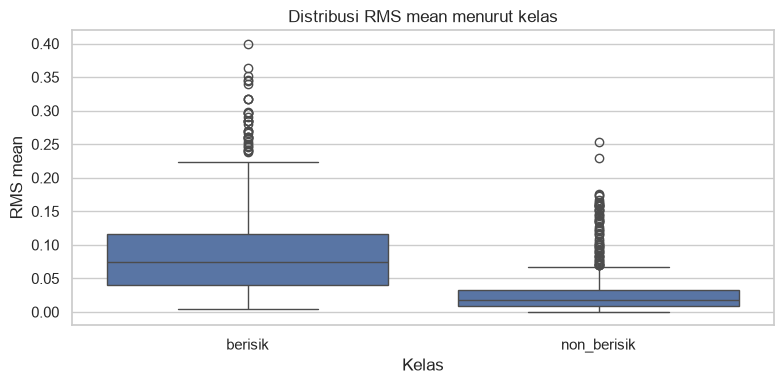

In [6]:
feature_to_plot = "rms_mean"
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="label", y=feature_to_plot)
plt.title("Distribusi RMS mean menurut kelas")
plt.xlabel("Kelas")
plt.ylabel("RMS mean")
plt.tight_layout()
plt.show()

## 7. Bagi data latih dan data uji berdasarkan file sumber
Pembagian dilakukan berdasarkan `group_id`, bukan secara acak per segmen. Ini membantu mencegah kebocoran ketika beberapa segmen berasal dari satu rekaman. Jika dataset berisi sangat sedikit file unik per kelas, evaluasi akan kurang stabil; tambahkan rekaman bila memungkinkan.

In [7]:
feature_cols = [
    c for c in df.columns
    if c.startswith(("rms_", "spectral_centroid_", "zcr_", "mfcc_"))
]
X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df["label"]
groups = df["group_id"]

# Periksa jumlah file unik per kelas sebelum split berbasis grup.
files_per_class = df.groupby("label")["group_id"].nunique()
display(files_per_class.rename("jumlah_file_unik").to_frame())

if groups.nunique() < 2:
    raise ValueError("Minimal diperlukan 2 file audio unik untuk membagi data latih dan uji.")

splitter = GroupShuffleSplit(n_splits=30, test_size=0.20, random_state=RANDOM_STATE)
train_idx = test_idx = None
for candidate_train, candidate_test in splitter.split(X, y, groups=groups):
    if y.iloc[candidate_train].nunique() == 2 and y.iloc[candidate_test].nunique() == 2:
        train_idx, test_idx = candidate_train, candidate_test
        break

if train_idx is None:
    raise ValueError(
        "Tidak ditemukan pembagian train/test yang memuat kedua kelas. "
        "Tambahkan file unik pada masing-masing kelas (disarankan minimal 3 file per kelas)."
    )

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print("Jumlah segmen train:", len(X_train))
print("Jumlah segmen test :", len(X_test))
print("File unik train    :", groups_train.nunique())
print("File unik test     :", groups_test.nunique())
print("Irisan file train/test:", len(set(groups_train) & set(groups_test)))
display(y_train.value_counts().rename("jumlah_segmen_train").to_frame())
display(y_test.value_counts().rename("jumlah_segmen_test").to_frame())

,jumlah_file_unik
label,
berisik,100
non_berisik,100


Jumlah segmen train: 985
Jumlah segmen test : 249
File unik train    : 160
File unik test     : 40
Irisan file train/test: 0


,jumlah_segmen_train
label,
non_berisik,493
berisik,492


,jumlah_segmen_test
label,
berisik,132
non_berisik,117


## 8. Latih model Random Forest
Imputer menangani nilai fitur yang hilang. Random Forest menjadi model baseline sesuai materi. Parameter di bawah adalah titik awal yang bisa dievaluasi lebih lanjut, bukan jaminan hasil terbaik.

In [8]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
print("Pelatihan selesai.")

Pelatihan selesai.


## 9. Evaluasi pada data uji
Selain accuracy, perhatikan precision, recall, F1-score per kelas, balanced accuracy, dan confusion matrix. Karena segmen dari satu file bisa berkorelasi, skor per segmen bukan satu-satunya gambaran performa; uji juga pada rekaman/lokasi/perangkat yang benar-benar baru.

Accuracy          : 0.859
Balanced accuracy : 0.857
Macro F1-score    : 0.858

Classification report:
              precision    recall  f1-score   support

     berisik       0.85      0.89      0.87       132
 non_berisik       0.87      0.82      0.85       117

    accuracy                           0.86       249
   macro avg       0.86      0.86      0.86       249
weighted avg       0.86      0.86      0.86       249



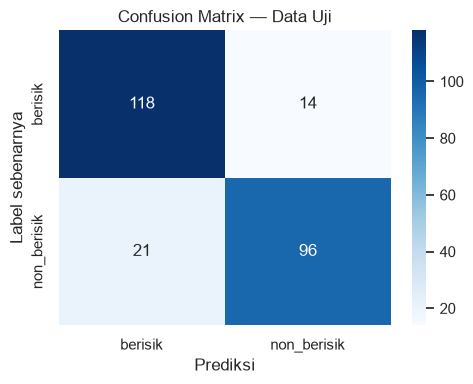

In [9]:
y_pred = model.predict(X_test)

print(f"Accuracy          : {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Macro F1-score    : {f1_score(y_test, y_pred, average='macro'):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Sesuaikan label dengan kelas yang baru
labels = ["berisik", "non_berisik"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Prediksi")
plt.ylabel("Label sebenarnya")
plt.title("Confusion Matrix — Data Uji")
plt.tight_layout()
plt.show()

## 10. Feature importance
Feature importance menunjukkan fitur yang sering digunakan model untuk membuat pemisahan. Nilai ini tidak membuktikan hubungan sebab-akibat dan dapat bias terhadap fitur tertentu.

,importance
rms_mean,0.120225
mfcc_1_mean,0.104125
rms_std,0.081053
mfcc_5_mean,0.055145
mfcc_13_std,0.038714
mfcc_3_mean,0.035094
spectral_centroid_mean,0.034657
mfcc_2_mean,0.033732
zcr_mean,0.032559
mfcc_6_mean,0.031668


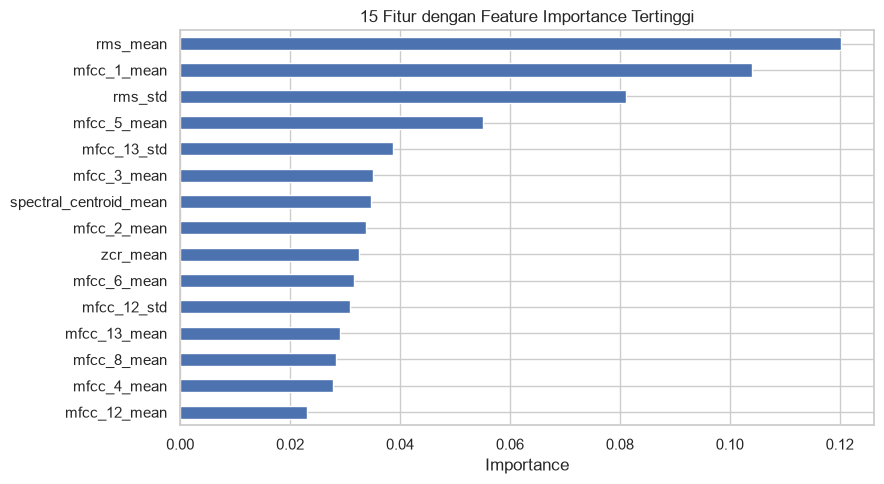

In [10]:
rf = model.named_steps["classifier"]
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

display(importance.head(15).rename("importance").to_frame())

plt.figure(figsize=(9, 5))
importance.head(15).sort_values().plot(kind="barh")
plt.title("15 Fitur dengan Feature Importance Tertinggi")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 11. Simpan model dan metadata
Model disimpan bersama daftar nama fitur, sample rate, dan durasi segmen. Saat nanti diintegrasikan ke website, gunakan fungsi ekstraksi fitur dan urutan fitur yang sama persis.

In [11]:
ARTIFACT_DIR = OUTPUT_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

artifact = {
    "model": model,
    "feature_columns": feature_cols,
    "sample_rate": SAMPLE_RATE,
    "segment_seconds": SEGMENT_SECONDS,
    "min_segment_seconds": MIN_SEGMENT_SECONDS,
    "labels": ["berisik", "non_berisik"],
    "feature_description": "RMS, Spectral Centroid, ZCR, dan MFCC 1-13 (mean/std)",
}

model_path = ARTIFACT_DIR / "audio_classifier_random_forest.joblib"
joblib.dump(artifact, model_path)
print("Model tersimpan di:", model_path.resolve())

Model tersimpan di: D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\output\artifacts\audio_classifier_random_forest.joblib


## 12. Prediksi audio baru dan visualisasi time series

Ganti `TEST_AUDIO_PATH` dengan lokasi file audio baru. Fungsi prediksi mengklasifikasikan setiap segmen, menentukan ringkasan mayoritas, menyimpan hasil prediksi ke CSV, dan menampilkan waveform (time series amplitudo terhadap waktu). Warna pada grafik menunjukkan prediksi setiap segmen: merah untuk **berisik**, hijau untuk **non-berisik**.

Prediksi ringkasan file: NON BERISIK
Distribusi prediksi per segmen:


,segmen,waktu_mulai_detik,waktu_selesai_detik,prediksi,probabilitas_berisik
0,1,0,5.0,non_berisik,0.367375
1,2,5,10.0,berisik,0.568958
2,3,10,15.0,non_berisik,0.271583
3,4,15,20.0,non_berisik,0.138042
4,5,20,25.0,non_berisik,0.244167
5,6,25,30.0,non_berisik,0.281500


CSV prediksi tersimpan: D:\SEMESTER5\PSD\KELOMPOK\TUGAS SUARA\output\prediksi_cobasuara1.csv


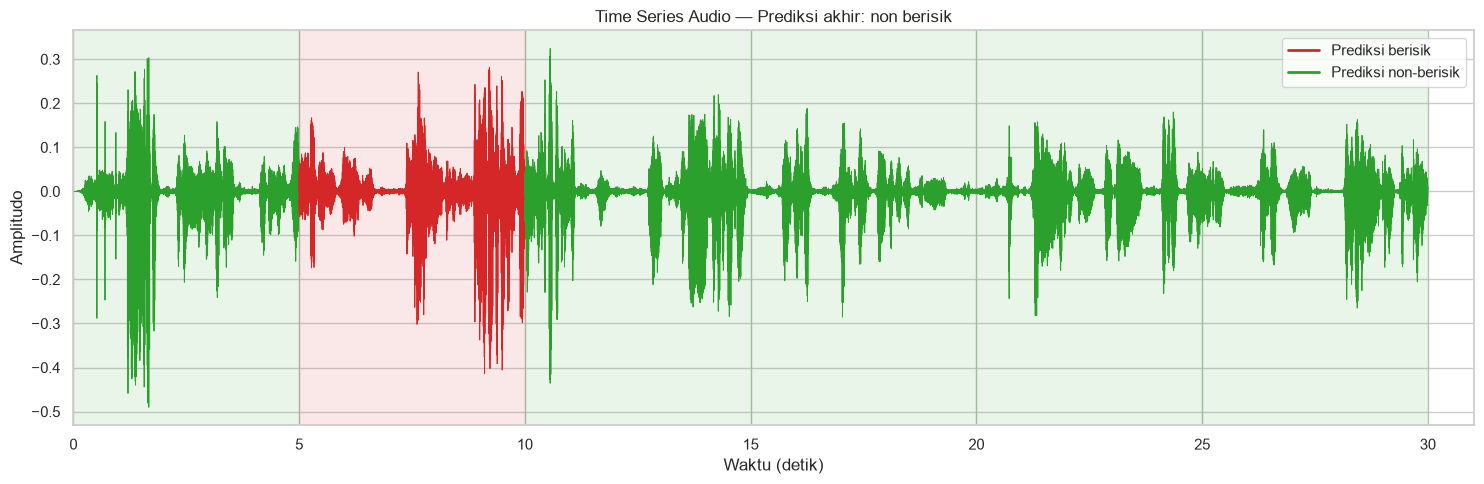

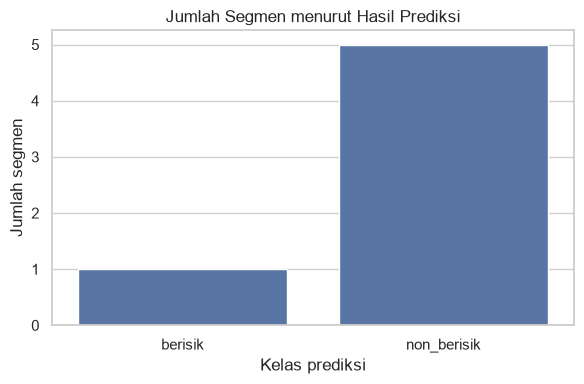

In [12]:
# Ganti dengan path audio yang ingin diuji.
TEST_AUDIO_PATH = Path("cobasuara1.mp3")

def predict_audio_file(audio_path, artifact):
    audio_path = Path(audio_path)
    sr = artifact["sample_rate"]
    segment_seconds = artifact["segment_seconds"]
    y_audio = load_audio(audio_path, sr=sr)

    segments = audio_to_segments(
        audio_path, sr=sr, segment_seconds=segment_seconds
    )
    if not segments:
        raise ValueError("Audio tidak cukup panjang untuk dianalisis.")

    feature_rows = [extract_features(seg, sr) for seg in segments]
    X_new = pd.DataFrame(feature_rows).reindex(columns=artifact["feature_columns"])
    predictions = artifact["model"].predict(X_new)

    # Probabilitas kelas berisik bila model mendukung predict_proba.
    probabilities = None
    if hasattr(artifact["model"], "predict_proba"):
        proba = artifact["model"].predict_proba(X_new)
        classes = list(artifact["model"].named_steps["classifier"].classes_)
        if "berisik" in classes:
            probabilities = proba[:, classes.index("berisik")]

    starts = np.arange(len(predictions)) * segment_seconds
    ends = np.minimum(starts + segment_seconds, len(y_audio) / sr)
    segment_results = pd.DataFrame({
        "segmen": np.arange(1, len(predictions) + 1),
        "waktu_mulai_detik": starts,
        "waktu_selesai_detik": ends,
        "prediksi": predictions
    })
    if probabilities is not None:
        segment_results["probabilitas_berisik"] = probabilities

    counts = pd.Series(predictions).value_counts()
    final_label = counts.idxmax()
    return final_label, segment_results, y_audio


if TEST_AUDIO_PATH.exists():
    loaded_artifact = joblib.load(model_path)
    final_label, segment_results, y_audio = predict_audio_file(
        TEST_AUDIO_PATH, loaded_artifact
    )

    print("Prediksi ringkasan file:", final_label.upper().replace("_", " "))
    print("Distribusi prediksi per segmen:")
    display(segment_results)

    prediction_csv = OUTPUT_DIR / f"prediksi_{TEST_AUDIO_PATH.stem}.csv"
    segment_results.to_csv(prediction_csv, index=False, encoding="utf-8-sig")
    print(f"CSV prediksi tersimpan: {prediction_csv.resolve()}")

    # Visualisasi time series: waveform dan warna prediksi per segmen.
    sr = loaded_artifact["sample_rate"]
    time_axis = np.arange(len(y_audio)) / sr
    fig, ax = plt.subplots(figsize=(15, 5))

    color_map = {"berisik": "tab:red", "non_berisik": "tab:green"}
    for _, row in segment_results.iterrows():
        start = float(row["waktu_mulai_detik"])
        end = min(float(row["waktu_selesai_detik"]), len(y_audio) / sr)
        mask = (time_axis >= start) & (time_axis < end)
        label = row["prediksi"]
        ax.plot(
            time_axis[mask], y_audio[mask],
            color=color_map.get(label, "tab:blue"),
            linewidth=0.65,
            label=label.replace("_", " ") if row["segmen"] == 1 else None
        )
        ax.axvspan(start, end, color=color_map.get(label, "tab:blue"), alpha=0.10)

    # Legend khusus agar kedua kelas tetap tampil meskipun hanya satu kelas terprediksi.
    from matplotlib.lines import Line2D
    legend_items = [
        Line2D([0], [0], color="tab:red", lw=2, label="Prediksi berisik"),
        Line2D([0], [0], color="tab:green", lw=2, label="Prediksi non-berisik")
    ]
    ax.legend(handles=legend_items, loc="upper right")
    ax.set_title(f"Time Series Audio — Prediksi akhir: {final_label.replace('_', ' ')}")
    ax.set_xlabel("Waktu (detik)")
    ax.set_ylabel("Amplitudo")
    ax.set_xlim(0, len(y_audio) / sr)
    plt.tight_layout()
    plt.show()

    # Ringkasan jumlah segmen per kelas.
    pred_counts = segment_results["prediksi"].value_counts().reindex(
        ["berisik", "non_berisik"], fill_value=0
    )
    plt.figure(figsize=(6, 4))
    sns.barplot(x=pred_counts.index, y=pred_counts.values)
    plt.title("Jumlah Segmen menurut Hasil Prediksi")
    plt.xlabel("Kelas prediksi")
    plt.ylabel("Jumlah segmen")
    plt.tight_layout()
    plt.show()
else:
    print(
        f"File uji belum ditemukan: {TEST_AUDIO_PATH.resolve()}\n"
        "Ubah TEST_AUDIO_PATH ke file audio yang tersedia. "
        "Bagian prediksi dan visualisasi akan berjalan setelah file ditemukan."
    )

## Catatan sebelum model dipakai

1. CSV `output/inventaris_audio.csv` dibuat setelah pemeriksaan jumlah file.
2. CSV `output/fitur_audio.csv` berisi fitur numerik per segmen beserta label dan metadata sumber.
3. CSV `output/prediksi_NAMA_FILE.csv` dibuat ketika file uji tersedia dan berhasil diprediksi.
4. Grafik time series menunjukkan amplitudo waveform; warna menunjukkan kelas prediksi model per segmen, bukan label kebenaran yang diketahui.
5. Skor yang bagus pada satu pembagian data belum menjamin model bekerja pada rekaman baru. Tambahkan rekaman bervariasi dan hindari kebocoran antara data latih dan uji.
6. Pastikan label “berisik/non-berisik” konsisten. Suara keras tidak selalu berarti ramai.
7. File model `.joblib` hanya aman dimuat jika berasal dari sumber tepercaya.